In [55]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

In [56]:
# Uploading the csv file

book = pd.read_csv('C:\DecodeLabs_Internship\Projects\Project 3 Recommendation-System\dataset\Books.csv')
user = pd.read_csv(r'C:\DecodeLabs_Internship\Projects\Project 3 Recommendation-System\dataset\Users.csv')
rating = pd.read_csv('C:\DecodeLabs_Internship\Projects\Project 3 Recommendation-System\dataset\Ratings.csv')

display(book.head())
display(user.head())
display(rating.head())

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...


,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN


,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


### Understanding the data

In [57]:
# Shape of the data
print('Shape of the books', book.shape)
print('-*' * 50)

print('Shape of the user', user.shape)
print('-*' * 50)

print('Shape of the rating', rating.shape)
print('-*' * 50)


# Information of the data
book.info()
print('-*' * 50)

user.info()
print('-*' * 50)

rating.info()
print('-*' * 50)


# Missing values
print('Total missing books: \n', book.isnull().sum())
print('-*' * 50)

print('Total missing user: \n', user.isnull().sum())
print('-*' * 50)

print('Total missing rating: \n', rating.isnull().sum())
print('-*' * 50)


# Duplicate values
print('Total duplicate books:', book.duplicated().sum())
print('-*' * 50)

print('Total duplicate user:', user.duplicated().sum())
print('-*' * 50)

print('Total duplicate rating:', rating.duplicated().sum())
print('-*' * 50)

Shape of the books (271360, 8)
-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
Shape of the user (278858, 3)
-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
Shape of the rating (1149780, 3)
-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*-*
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271360 entries, 0 to 271359
Data columns (total 8 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   ISBN                 271360 non-null  object
 1   Book-Title           271360 non-null  object
 2   Book-Author          271358 non-null  object
 3   Year-Of-Publication  271360 non-null  object
 4   Publisher            271358 non-null  object
 5   Image-URL-S          271360 non-null  object
 6   Image-URL-M          271360 non-null  object
 7   Image-URL-L          271357 non-null  

### Exploratory Data Analysis (EDA)

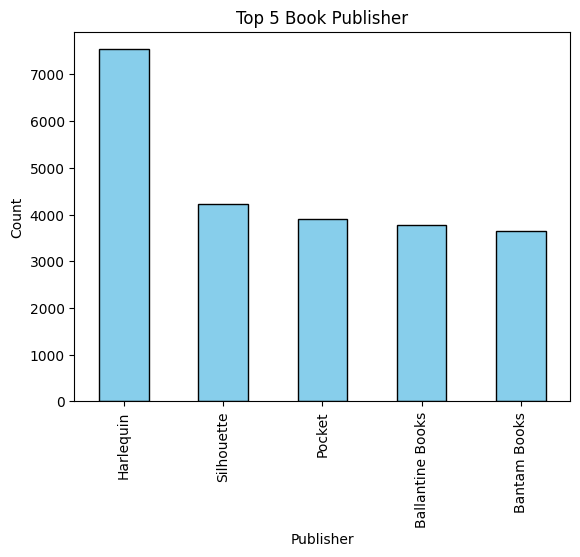

In [58]:
# Top 5 book publishers
top_5_publisher = book['Publisher'].value_counts().head()

top_5_publisher.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Top 5 Book Publisher')
plt.ylabel('Count')
plt.show()

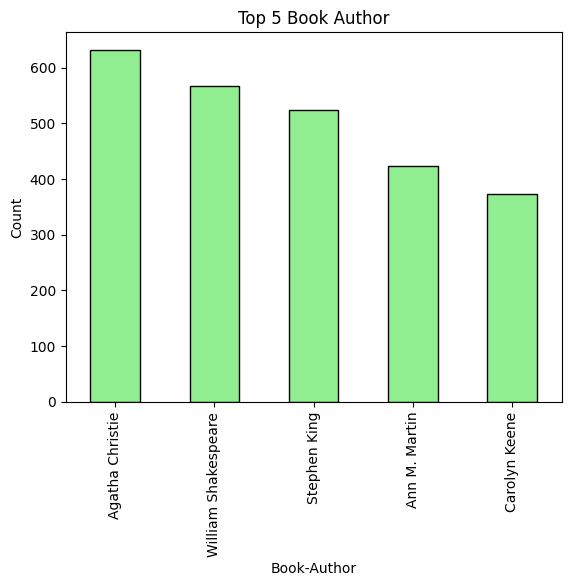

In [59]:
# Top 5 book publishers
top_5_publisher = book['Book-Author'].value_counts().head()

top_5_publisher.plot(kind='bar', color='lightgreen', edgecolor='black')
plt.title('Top 5 Book Author')
plt.ylabel('Count')
plt.show()

### Popularity based Recommendation System

In [60]:
rating_with_book = rating.merge(book, on='ISBN')
rating_with_book.head()

,User-ID,ISBN,Book-Rating,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,276725,034545104X,0,Flesh Tones: A Novel,M. J. Rose,2002,Ballantine Books,http://images.amazon.com/images/P/034545104X.0...,http://images.amazon.com/images/P/034545104X.0...,http://images.amazon.com/images/P/034545104X.0...
1,276726,0155061224,5,Rites of Passage,Judith Rae,2001,Heinle,http://images.amazon.com/images/P/0155061224.0...,http://images.amazon.com/images/P/0155061224.0...,http://images.amazon.com/images/P/0155061224.0...
2,276727,0446520802,0,The Notebook,Nicholas Sparks,1996,Warner Books,http://images.amazon.com/images/P/0446520802.0...,http://images.amazon.com/images/P/0446520802.0...,http://images.amazon.com/images/P/0446520802.0...
3,276729,052165615X,3,Help!: Level 1,Philip Prowse,1999,Cambridge University Press,http://images.amazon.com/images/P/052165615X.0...,http://images.amazon.com/images/P/052165615X.0...,http://images.amazon.com/images/P/052165615X.0...
4,276729,0521795028,6,The Amsterdam Connection : Level 4 (Cambridge ...,Sue Leather,2001,Cambridge University Press,http://images.amazon.com/images/P/0521795028.0...,http://images.amazon.com/images/P/0521795028.0...,http://images.amazon.com/images/P/0521795028.0...


In [61]:
# Number of rating based on the Title
rating_num = (
    rating_with_book.groupby('Book-Title')['Book-Rating']
    .count()
    .reset_index(name='num_rating')
)


# Average of rating based on the Title
rating_avg = (
    rating_with_book.groupby('Book-Title')['Book-Rating']
    .mean()
    .reset_index(name='avg_rating')
)


# Combination of rating_num and rating_avg
popular_df = rating_avg.merge(rating_num, on='Book-Title')

display(popular_df.head())
display(popular_df.shape)

,Book-Title,avg_rating,num_rating
0,A Light in the Storm: The Civil War Diary of ...,2.25,4
1,Always Have Popsicles,0.00,1
2,Apple Magic (The Collector's series),0.00,1
3,"Ask Lily (Young Women of Faith: Lily Series, ...",8.00,1
4,Beyond IBM: Leadership Marketing and Finance ...,0.00,1


(241071, 3)

In [62]:
# Filtering top rated books
popular_df = (
    popular_df[popular_df['num_rating'] >= 300]
    .sort_values('avg_rating', ascending=False )
    .head(50)
    .reset_index()
)

popular_df = (
    popular_df.merge(book, on='Book-Title')
    .drop_duplicates('Book-Title')[['Book-Title', 'avg_rating', 'num_rating', 'Book-Author', 'Image-URL-M', 'Publisher']]
)

popular_df.head()

,Book-Title,avg_rating,num_rating,Book-Author,Image-URL-M,Publisher
0,Harry Potter and the Prisoner of Azkaban (Book 3),5.852804,428,J. K. Rowling,http://images.amazon.com/images/P/0439136350.0...,Scholastic
3,Harry Potter and the Goblet of Fire (Book 4),5.824289,387,J. K. Rowling,http://images.amazon.com/images/P/0439139597.0...,Scholastic
5,Harry Potter and the Order of the Phoenix (Boo...,5.501441,347,J. K. Rowling,http://images.amazon.com/images/P/043935806X.0...,Scholastic
9,Harry Potter and the Chamber of Secrets (Book 2),5.183453,556,J. K. Rowling,http://images.amazon.com/images/P/0439064872.0...,Scholastic
12,The Fellowship of the Ring (The Lord of the Ri...,4.948370,368,J.R.R. TOLKIEN,http://images.amazon.com/images/P/0345339703.0...,Del Rey


### Collaborative Filtering Based Recommendation System

In [63]:
# Filtering famous users
x = rating_with_book.groupby('User-ID').count()['Book-Rating'] > 200
famous_user = x[x].index


filter_rating = rating_with_book[rating_with_book['User-ID'].isin(famous_user)]
filter_rating


# Filtering famous books
y = filter_rating.groupby('Book-Title').count()['Book-Rating'] >= 50
famous_books = y[y].index


final_rating = filter_rating[filter_rating['Book-Title'].isin(famous_books)]
final_rating


# Creating a pivot table
pt = final_rating.pivot_table(index='Book-Title', columns='User-ID', values='Book-Rating')
pt.fillna(0, inplace=True)

pt.head()


User-ID,254,2276,2766,2977,3363,4017,4385,6251,6323,6543,...,271705,273979,274004,274061,274301,274308,275970,277427,277639,278418
Book-Title,,,,,,,,,,,,,,,,,,,,,
1984,9.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1st to Die: A Novel,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2nd Chance,0.0,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4 Blondes,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
A Bend in the Road,0.0,0.0,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [64]:
# Figure-outing similarity score
from sklearn.metrics.pairwise import cosine_similarity

similarity_score = cosine_similarity(pt)

In [67]:
def recommend(book_name, top_n=10):
    # Check whether the book exists
    if book_name not in pt.index:
        print(f"'{book_name}' not found in the dataset.")
        return

    # Fetch the book index
    book_index = np.where(pt.index == book_name)[0][0]

    # Calculate and sort similarity scores
    similar_books = sorted(
        enumerate(similarity_score[book_index]),
        key=lambda x: x[1],
        reverse=True
    )

    # Exclude the input book and select top N recommendations
    recommendations = similar_books[1:top_n + 1]

    # Display recommendations
    print(f"\nRecommended books similar to '{book_name}':\n")

    for rank, (index, score) in enumerate(recommendations, start=1):
        print(f"{rank}. {pt.index[index]} (Similarity: {score:.2f})")

In [73]:
recommend('Pop Goes the Weasel')


Recommended books similar to 'Pop Goes the Weasel':

1. The Clinic (Alex Delaware Novels (Paperback)) (Similarity: 0.30)
2. 1st to Die: A Novel (Similarity: 0.28)
3. Cat &amp; Mouse (Alex Cross Novels) (Similarity: 0.27)
4. The Woman Next Door (Similarity: 0.27)
5. The Summons (Similarity: 0.27)
6. Roses Are Red (Alex Cross Novels) (Similarity: 0.27)
7. Second Nature (Similarity: 0.26)
8. The General's Daughter (Similarity: 0.26)
9. 2nd Chance (Similarity: 0.25)
10. Cradle and All (Similarity: 0.25)
